In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.io as sio
import matplotlib.pyplot as plt

from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from scipy.stats import norm
# import utilities as utils

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import math

class GaussianNetwork(nn.Module):
    """
    Neural network mapping x -> parameters of an N_y-dimensional Gaussian.

    Outputs
    -------
    mean : Tensor, shape (..., N_y)
        Gaussian mean.

    scale_tril : Tensor, shape (..., N_y, N_y)
        Lower-triangular Cholesky factor L such that
            covariance = L @ L.T

    covariance : Tensor, shape (..., N_y, N_y)
        Gaussian covariance matrix.
    """

    def __init__(
        self,
        input_dim,
        output_dim,
        hidden_dims=(128, 128),
        min_std=1e-4,
    ):
        super().__init__()

        self.output_dim = output_dim
        self.min_std = min_std

        # Shared feature-processing network
        layers = []
        d = input_dim

        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(d, hidden_dim),
                nn.ReLU(),
                nn.Dropout(p=0.1),
            ])
            d = hidden_dim

        self.backbone = nn.Sequential(*layers)

        # Mean requires N_y parameters
        self.mean_head = nn.Linear(d, output_dim)

        # Lower triangular matrix requires
        # N_y * (N_y + 1) / 2 parameters
        n_tril = output_dim * (output_dim + 1) // 2
        self.cholesky_head = nn.Linear(d, n_tril)

        # Indices of lower-triangular matrix elements
        tril_indices = torch.tril_indices(
            row=output_dim,
            col=output_dim,
            offset=0,
        )

        self.register_buffer("tril_indices", tril_indices)


    def forward(self, x):
        h = self.backbone(x)

        # Mean
        mean = self.mean_head(h)

        # Raw parameters for Cholesky factor
        raw_tril = self.cholesky_head(h)

        batch_shape = x.shape[:-1]

        L = torch.zeros(
            *batch_shape,
            self.output_dim,
            self.output_dim,
            device=x.device,
            dtype=x.dtype,
        )

        L[..., self.tril_indices[0], self.tril_indices[1]] = raw_tril

        # Diagonal must be positive.
        diag_idx = torch.arange(self.output_dim, device=x.device)

        raw_diag = L[..., diag_idx, diag_idx]

        L[..., diag_idx, diag_idx] = (
            F.softplus(raw_diag) + self.min_std
        )

        # covariance = L @ L.transpose(-1, -2)

        # return mean, L, covariance
        return mean, L

class GaussianNetworkV2(nn.Module):
    """
    Maps input features to a multivariate Gaussian.

    Inputs
    ------
    x : Tensor, shape (..., input_dim)

    Outputs
    -------
    mean : Tensor, shape (..., output_dim)
    L : Tensor, shape (..., output_dim, output_dim)
        Lower-triangular Cholesky factor.
    """

    def __init__(
        self,
        input_dim,
        output_dim,
        hidden_dims=(),
        dropout=0.0,
        min_std=1e-4,
        init_std=1.0,
    ):
        super().__init__()

        self.output_dim = output_dim
        self.min_std = min_std

        if init_std <= min_std:
            raise ValueError("init_std must exceed min_std")

        # Optional feature-processing network
        layers = []
        d = input_dim

        for hidden_dim in hidden_dims:
            layers.extend([
                nn.Linear(d, hidden_dim),
                nn.ReLU(),
            ])

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            d = hidden_dim

        self.backbone = nn.Sequential(*layers)

        # Gaussian output heads
        self.mean_head = nn.Linear(d, output_dim)

        n_tril = output_dim * (output_dim + 1) // 2
        self.cholesky_head = nn.Linear(d, n_tril)

        tril_indices = torch.tril_indices(
            output_dim, output_dim
        )
        self.register_buffer("tril_indices", tril_indices)

        # Initialize Cholesky output near init_std * I
        with torch.no_grad():
            nn.init.normal_(
                self.cholesky_head.weight,
                std=1e-3,
            )
            nn.init.zeros_(self.cholesky_head.bias)

            diag_mask = (
                tril_indices[0] == tril_indices[1]
            )

            # Inverse softplus
            diag_bias = math.log(
                math.expm1(init_std - min_std)
            )

            self.cholesky_head.bias[diag_mask] = diag_bias

    def forward(self, x):
        h = self.backbone(x)

        mean = self.mean_head(h)
        raw_tril = self.cholesky_head(h)

        # Construct lower-triangular matrix
        L = raw_tril.new_zeros(
            *raw_tril.shape[:-1],
            self.output_dim,
            self.output_dim,
        )

        L[
            ...,
            self.tril_indices[0],
            self.tril_indices[1],
        ] = raw_tril

        # Positive diagonal
        raw_diag = torch.diagonal(
            L, dim1=-2, dim2=-1
        )

        L = (
            torch.tril(L, diagonal=-1)
            + torch.diag_embed(
                F.softplus(raw_diag) + self.min_std
            )
        )

        return mean, L

class GRUGaussianNetwork(nn.Module):
    def __init__(
        self,
        input_dim,
        output_dim,
        hidden_dim=64,
        num_layers=1,
        head_hidden_dims=(64,),
        head_dropout=0.0,
        min_std=1e-4,
    ):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
        )

        self.gaussian_head = GaussianNetworkV2(
            input_dim=hidden_dim,
            output_dim=output_dim,
            hidden_dims=head_hidden_dims,
            dropout=head_dropout,
            min_std=min_std,
        )

    def forward(self, x, h=None, output_each_step=True):
        # x: (batch, time, input_dim)
        # h: optional initial recurrent hidden state

        h_seq, h_final = self.gru(x, h)

        if output_each_step:
            # (batch, time, hidden_dim)
            features = h_seq
        else:
            # (batch, hidden_dim)
            features = h_seq[:, -1, :]

        mean, L = self.gaussian_head(features)

        return mean, L, h_final

class RecurrentGaussianNetwork(nn.Module):
    def __init__(
        self,
        input_dim,
        output_dim,
        hidden_dim=64,
        num_layers=1,
        head_hidden_dims=(64,),
        head_dropout=0.0,
        min_std=1e-4,
        nonlinearity="tanh",
    ):
        super().__init__()

        # Vanilla recurrent network
        self.rnn = nn.RNN(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            nonlinearity=nonlinearity,
            batch_first=True,
        )

        # Gaussian output network
        self.gaussian_head = GaussianNetworkV2(
            input_dim=hidden_dim,
            output_dim=output_dim,
            hidden_dims=head_hidden_dims,
            dropout=head_dropout,
            min_std=min_std,
        )

    def forward(self, x, h=None, output_each_step=True):
        """
        Parameters
        ----------
        x : Tensor, shape (batch, time, input_dim)
            Input sequences.

        h : Tensor, optional
            Initial hidden state, shape
            (num_layers, batch, hidden_dim).

        Returns
        -------
        mean : Tensor, shape (batch, time, output_dim)
            Gaussian mean at each time step.

        L : Tensor, shape (batch, time, output_dim, output_dim)
            Cholesky factor at each time step.

        h_final : Tensor, shape (num_layers, batch, hidden_dim)
            Final recurrent hidden state.
        """

        # Process temporal sequence
        h_seq, h_final = self.rnn(x, h)

        if output_each_step:
            # (batch, time, hidden_dim)
            features = h_seq
        else:
            # (batch, hidden_dim)
            features = h_seq[:, -1, :]

        mean, L = self.gaussian_head(features)

        return mean, L, h_final

def gaussian_change_point_process(
    T,
    B,
    hazard,
    emission_cov=torch.tensor([[1.]]),
    source_mean=torch.tensor([0.]),
    source_cov=torch.tensor([[1.]]),
    start_Y=None,
    end_Y=None,
    return_source_index=False,
):
    """
    Simulate B independent N-dimensional Gaussian change-point processes.

    Parameters
    ----------
    T : int
        Number of time points per sequence.
    B : int
        Number of independent sequences.
    hazard : float
        Probability of a source change between consecutive time points.
    emission_cov : Tensor, shape (N, N)
        Covariance of observations around the current source.
    source_mean : Tensor, shape (N,)
        Mean of the distribution from which sources are drawn.
    source_cov : Tensor, shape (N, N)
        Covariance of the distribution from which sources are drawn.
    start_Y : Tensor, shape (N,) or (B, N), optional
        Specified initial source(s).
    end_Y : Tensor, shape (N,) or (B, N), optional
        Specified final source(s).

    Returns
    -------
    X : Tensor, shape (B, T, N)
        Sequences of observations.
    Y : Tensor, shape (B, T, N)
        Sequences of source locations.
    source_idx : Tensor, shape (B, T)
        Indices of the sources for each time point (only if return_source_index is True).
    """

    if start_Y is not None and end_Y is not None:
        raise ValueError("Only one of start_Y and end_Y can be specified.")

    N = source_mean.shape[0]

    # Generate independent change points for each sequence
    changes = torch.rand(B, T, device=source_mean.device) < hazard
    changes[:, 0] = True

    # Assign source indices, unique across all batches
    source_idx = torch.cumsum(changes.reshape(-1).long(), dim=0) - 1
    source_idx = source_idx.reshape(B, T)
    n_sources = source_idx[-1, -1].item() + 1

    # Draw all sources
    source_dist = torch.distributions.MultivariateNormal(
        source_mean, covariance_matrix=source_cov
    )
    sources = source_dist.sample((n_sources,))

    # Optionally specify initial or final sources
    if start_Y is not None:
        start_Y = torch.as_tensor(
            start_Y, device=sources.device, dtype=sources.dtype
        ).broadcast_to(B, N)
        sources[source_idx[:, 0]] = start_Y

    elif end_Y is not None:
        end_Y = torch.as_tensor(
            end_Y, device=sources.device, dtype=sources.dtype
        ).broadcast_to(B, N)
        sources[source_idx[:, -1]] = end_Y

    # Assign sources to each batch and time point
    Y = sources[source_idx]

    # Draw independent Gaussian observation noise
    emission_dist = torch.distributions.MultivariateNormal(
        torch.zeros_like(source_mean),
        covariance_matrix=emission_cov
    )
    X = Y + emission_dist.sample((B, T))

    if return_source_index:
        return X, Y, source_idx
    else:
        return X, Y

def gaussian_kl_divergence_torch(
    true_mean,
    true_scale_tril,
    approx_mean,
    approx_scale_tril,
):
    true_dist = torch.distributions.MultivariateNormal(
        loc=true_mean,
        scale_tril=true_scale_tril,
    )

    approx_dist = torch.distributions.MultivariateNormal(
        loc=approx_mean,
        scale_tril=approx_scale_tril,
    )

    return torch.distributions.kl_divergence(
        true_dist,
        approx_dist,
    ) / torch.log(torch.tensor(2.0))

def I_XR_gaussian_mc(model, data_generator, N_XR=10000):
    x, _ = data_generator((1, N_XR))
    mean, L, _ = model(x)
    # time, output_size = mean.shape
    f_RgX = torch.distributions.MultivariateNormal(
        loc=mean,
        scale_tril=L,
    )
    rgx = f_RgX.rsample() # dim (1, N_XR, output_size)
    # f_rgx = f_RgX.log_prob(rgx).exp() # dim (1, N_XR)
    # f_rgx_cross = f_RgX.log_prob(rgx.repeat(N_XR, 1, 1).transpose(0,1)).exp() # dim (N_XR, N_XR)
    # f_r = f_rgx_cross.sum(dim=0, keepdims=True) / N_XR
    # return torch.sum(torch.log2(f_rgx / f_r)) / N_XR
    log_f_rgx = f_RgX.log_prob(rgx)
    log_f_rgx_cross = f_RgX.log_prob(rgx.repeat(N_XR,1,1).transpose(0,1))
    log_f_r = log_f_rgx_cross.logsumexp(dim=0, keepdim=True) - torch.log(torch.tensor(N_XR, dtype=torch.float))
    return torch.sum(log_f_rgx - log_f_r) / torch.log(torch.tensor(2.0)) / N_XR

def I_RY_gaussian_mc(model, data_generator, N_XRY=10000):
    x, y = data_generator((1, N_XR))
    mean, L, _ = model(x)
    # time, output_size = mean.shape
    f_RgX = torch.distributions.MultivariateNormal(
        loc=mean,
        scale_tril=L,
    )
    rgx = f_RgX.rsample()

def I_RY_gaussian_mc_alt(model, data_generator, N_RgX=100, N_Y=100):
    x, y = data_generator((N_Y, N_RgX))
    mean, L, _ = model(x)
    f_RgX = torch.distributions.MultivariateNormal(
        loc=mean,
        scale_tril=L,
    )
    rgx = f_RgX.rsample()
    


def I_XR_gaussian_mc_alt(model, data_generator, N_RgX=1000, N_X=1000):
    x = data_generator((1, N_X))
    mean, L, _ = model(x)
    time, output_size = mean.shape[1], mean.shape[2]
    f_RgX = torch.distributions.MultivariateNormal(
        loc=mean,
        scale_tril=L,
    ) # dim (1, time, output_size)
    rgx = f_RgX.rsample((N_RgX,)) # dim (N_RgX, time, output_size)
    f_rgx = f_RgX.log_prob(rgx).exp() # dim (N_RgX, time)
    x_ = data_generator((N_RgX, N_X))
    mean_, L_, _ = model(x_)
    f_RgX_ = torch.distributions.MultivariateNormal(
        loc=mean_,
        scale_tril=L_,
    )
    f_rgx_ = f_RgX_.log_prob(rgx).exp() # dim (N_RgX, time)
    f_r = f_rgx_.sum(dim=0,keepdims=True) / N_X
    return torch.sum(torch.log2(f_rgx / f_r)) / (N_RgX * N_X)

    # for t in range(time):
    #     f_RgX = torch.distributions.MultivariateNormal(
    #         loc=mean[t],
    #         scale_tril=L[t],
    #     )
    #     for _rgx in range(N_RgX):
    #         r_ = f_RgX.rsample()
    #         x_ = data_generator((1, N_X))
    #         mean_, L_, _ = model(x_)
    #         f_r = (1/N_X) * torch.sum(torch.distributions.MultivariateNormal(
    #             loc=mean_,
    #             scale_tril=L_,
    #         ).log_prob(r_).exp())
    #         # I_XR

# def I_XR_gaussian_mc(mean, L, N_RgX=1000, N_X=1000):
#     time, output_size = mean.shape
#     I_XR = 0.0
#     for t in range(time):
#         f_RgX = torch.distributions.MultivariateNormal(
#             loc=mean[t],
#             scale_tril=L[t],
#         )
#         for _rgx in range(N_RgX):
#             r_ = f_RgX.rsample()
#             for _x in range(N_X):


In [3]:
a = torch.arange(10)
b = a.repeat((2,1))
b

tensor([[0, 1, 2, 3, 4, 5, 6, 7, 8, 9],
        [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]])

In [4]:
a = torch.arange(10)
a.repeat_interleave(2).reshape(10,2)

tensor([[0, 0],
        [1, 1],
        [2, 2],
        [3, 3],
        [4, 4],
        [5, 5],
        [6, 6],
        [7, 7],
        [8, 8],
        [9, 9]])

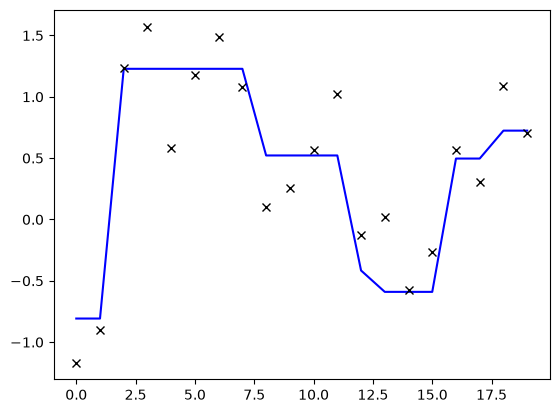

In [5]:
x, y = gaussian_change_point_process(
    T=20,
    B=1,
    hazard=0.1,
    emission_cov=torch.tensor([[0.1]]),
)
plt.plot(y[0, :, 0],'b-')
plt.plot(x[0, :, 0],'kx')
plt.show()

In [6]:
def I_XR_gaussian_mc(model, data_generator, N_XR=10000):
    x, _ = data_generator((1, N_XR))
    mean, L, _ = model(x)
    # time, output_size = mean.shape
    f_RgX = torch.distributions.MultivariateNormal(
        loc=mean,
        scale_tril=L,
    )
    rgx = f_RgX.rsample() # dim (1, N_XR, output_size)
    # f_rgx = f_RgX.log_prob(rgx).exp() # dim (1, N_XR)
    # f_rgx_cross = f_RgX.log_prob(rgx.repeat(N_XR, 1, 1).transpose(0,1)).exp() # dim (N_XR, N_XR)
    # f_r = f_rgx_cross.sum(dim=0, keepdims=True) / N_XR
    # return torch.sum(torch.log2(f_rgx / f_r)) / N_XR
    log_f_rgx = f_RgX.log_prob(rgx)
    log_f_rgx_cross = f_RgX.log_prob(rgx.repeat(N_XR,1,1).transpose(0,1))
    log_f_r = log_f_rgx_cross.logsumexp(dim=0, keepdim=True) - torch.log(torch.tensor(N_XR, dtype=torch.float))
    return torch.sum(log_f_rgx - log_f_r) / torch.log(torch.tensor(2.0)) / N_XR

In [107]:
# data_generator = lambda shape: gaussian_change_point_process(
#     T=shape[1],
#     B=shape[0],
#     hazard=0.1,
#     emission_cov=torch.tensor([[0.1]]),
# )[0]

# x = data_generator((1, 10000))
T = 10000
x, y = gaussian_change_point_process(
    T=T,
    B=1,
    hazard=0.1,
    emission_cov=torch.tensor([[0.1]]),
)
mean = y
f_RgX = torch.distributions.MultivariateNormal(
    loc=mean,
    covariance_matrix=torch.tensor([[0.1]]),
)

rgx = f_RgX.rsample()

f_rgx = f_RgX.log_prob(rgx).exp()
f_rgx_cross = f_RgX.log_prob(rgx.repeat(T,1,1).transpose(0,1)).exp()

f_r = f_rgx_cross.sum(dim=0, keepdims=True) / T

print(torch.sum(torch.log2(f_rgx / f_r)) / T)

log_f_rgx = f_RgX.log_prob(rgx)
log_f_rgx_cross = f_RgX.log_prob(rgx.repeat(T,1,1).transpose(0,1))
log_f_r = log_f_rgx_cross.logsumexp(dim=0, keepdim=True) - torch.log(torch.tensor(T, dtype=torch.float))

print(torch.sum(log_f_rgx - log_f_r) / torch.log(torch.tensor(2.0)) / T)

tensor(1.6242)
tensor(1.6242)


In [108]:
rgx.repeat(T,1,1).shape

torch.Size([10000, 10000, 1])

In [8]:
np.log(2*np.pi*np.e)/2

np.float64(1.4189385332046727)

In [ ]:
def I_RY_gaussian_mc(model, data_generator, N_XRY=10000, N_XgY=1000, W=50):
    x_n, y_n = data_generator((1, N_XRY))
    mean_n, L_n, _ = model(x_n)
    # time, output_size = mean.shape
    f_RgX = torch.distributions.MultivariateNormal(
        loc=mean_n,
        scale_tril=L_n,
    )
    rgx_n = f_RgX.rsample()
    log_f_rn_g_xn = f_RgX_n.log_prob(rgx_n).reshape((N,1))
    x_m, y_m = data_generator((N_XRY*N_XgY,W),)

In [109]:
N = 10000
W = 50
M = 1000
x_n, y_n = gaussian_change_point_process(T=N,B=1,hazard=0.1,emission_cov=torch.tensor([[0.1]]))

mean = y_n
f_RgX_n = torch.distributions.MultivariateNormal(
    loc=mean,
    covariance_matrix=torch.tensor([[0.1]]),
)

rgx_n = f_RgX_n.rsample() # .reshape((N,1))

log_f_rn_g_xn = f_RgX_n.log_prob(rgx_n).reshape((N,1))

x_m, y_m = gaussian_change_point_process(T=W,B=N*M,hazard=0.1,emission_cov=torch.tensor([[0.1]]),end_Y=y_n[0,:,:].repeat_interleave(M,dim=0))
y_m_last = y_m.reshape((N,M,W,1))[:,:,-1,:]

# imagine we can just get the distribution for the last time step
f_RgX_m = torch.distributions.MultivariateNormal(
    loc=y_m_last,
    covariance_matrix=torch.tensor([[0.1]]),
)

log_f_rn_g_xm = f_RgX_m.log_prob(rgx_n.reshape((N,1,1)))
log_f_rn_g_yn = log_f_rn_g_xm.logsumexp(dim=1,keepdim=True) - torch.log(torch.tensor(M, dtype=log_f_rn_g_xm.dtype))

log_f_rgx_n_cross = f_RgX_n.log_prob(rgx_n.repeat(N,1,1).transpose(0,1))
log_f_rn = (log_f_rgx_n_cross.logsumexp(dim=0, keepdim=True) - torch.log(torch.tensor(N, dtype=torch.float))).reshape((N,1))

print(torch.sum(log_f_rn_g_xn - log_f_rn) / torch.log(torch.tensor(2.0)) / N)
print(torch.sum(log_f_rn_g_yn - log_f_rn) / torch.log(torch.tensor(2.0)) / N)

tensor(1.6599)
tensor(1.6599)


In [45]:
model = RecurrentGaussianNetwork(
    input_dim=1,  # specify input dimension
    output_dim=1,  # specify output dimension
    hidden_dim=16,
    num_layers=1,
    head_hidden_dims=(),
    min_std=1e-4,
    nonlinearity="tanh",
)

# x, y = gaussian_change_point_process(
#     T=10,
#     B=5,
#     hazard=0.1,
# )

# mean, L, h = model(x)

N = 10000
W = 25
M = 1000
x, y = gaussian_change_point_process(T=N,B=1,hazard=0.1,emission_cov=torch.tensor([[0.1]]))

mean, L, _ = model(x)
f_RgX_n = torch.distributions.MultivariateNormal(
    loc=mean,
    covariance_matrix=L,
)

rgx_n = f_RgX_n.rsample() # .reshape((N,1))

log_f_rn_g_xn = f_RgX_n.log_prob(rgx_n).reshape((N,1))

x, y = gaussian_change_point_process(T=W,B=N*M,hazard=0.1,emission_cov=torch.tensor([[0.1]]),end_Y=y[0,:,:].repeat_interleave(M,dim=0))
y_last = y.reshape((N,M,W,1))[:,:,-1,:]

mean, L, _ = model(x, output_each_step=False)
mean = mean.reshape((N,M,-1))
L = L.reshape((N,M,1,1))

f_RgX_m = torch.distributions.MultivariateNormal(
    loc=mean,
    covariance_matrix=L,
)

log_f_rn_g_xm = f_RgX_m.log_prob(rgx_n.reshape((N,1,1)))
log_f_rn_g_yn = log_f_rn_g_xm.logsumexp(dim=1,keepdim=True) - torch.log(torch.tensor(M, dtype=log_f_rn_g_xm.dtype))

log_f_rgx_n_cross = f_RgX_n.log_prob(rgx_n.repeat(N,1,1).transpose(0,1))
log_f_rn = (log_f_rgx_n_cross.logsumexp(dim=0, keepdim=True) - torch.log(torch.tensor(N, dtype=torch.float))).reshape((N,1))
print(log_f_rn)
print(torch.sum(log_f_rn_g_xn - log_f_rn) / torch.log(torch.tensor(2.0)) / N)
print(torch.sum(log_f_rn_g_yn - log_f_rn) / torch.log(torch.tensor(2.0)) / N)

tensor([[-1.2716],
        [-1.2685],
        [-1.2703],
        ...,
        [-1.2681],
        [-1.2680],
        [-1.2681]], grad_fn=<ViewBackward0>)
tensor(-0.2197, grad_fn=<DivBackward0>)
tensor(-0.2210, grad_fn=<DivBackward0>)


In [48]:
def IB_obj_fast(
        beta,
        model,
        hazard,
        emission_cov,
        n_samples=1024,
        W=50,
):
    # sampling from overall distribution, (y_n, x_n, r_n) ~ f(y,x,r)
    x, y = gaussian_change_point_process(T=n_samples,B=1,hazard=hazard,emission_cov=emission_cov)
    mean, L, _ = model(x)
    f_RgX_n = torch.distributions.MultivariateNormal(
        loc=mean,
        covariance_matrix=L,
    )
    rgx_n = f_RgX_n.rsample() # .reshape((N,1))
    log_f_rn_g_xn = f_RgX_n.log_prob(rgx_n).reshape((n_samples,1))

    # sampling (x_m | y_n) ~ f(x|y_n) for f(r_n|y_n) estimation
    x, y = gaussian_change_point_process(T=W,B=n_samples*n_samples,hazard=hazard,emission_cov=emission_cov,end_Y=y[0,:,:].repeat_interleave(n_samples,dim=0))
    y_last = y.reshape((n_samples,n_samples,W,1))[:,:,-1,:]
    
    # defining f(r_n|x_m) for each sampled x_m
    mean, L, _ = model(x, output_each_step=False)
    mean = mean.reshape((n_samples,n_samples,-1))
    L = L.reshape((n_samples,n_samples,1,1))
    f_RgX_m = torch.distributions.MultivariateNormal(
        loc=mean,
        covariance_matrix=L,
    )

    # computing log f(r_n|x_m) for each r_n and x_m pair
    log_f_rn_g_xm = f_RgX_m.log_prob(rgx_n.reshape((n_samples,1,1)))

    # computing log f(r_n|y_n) by marginalizing over x_m samples
    log_f_rn_g_yn = log_f_rn_g_xm.logsumexp(dim=1,keepdim=True) - torch.log(torch.tensor(n_samples, dtype=log_f_rn_g_xm.dtype))

    # computing log f(r_i|x_j) for i,j in (1,2,...,n), so not just the diagonal elements (for estimation of f(r_n) below)
    log_f_rgx_n_cross = f_RgX_n.log_prob(rgx_n.repeat(n_samples,1,1).transpose(0,1))

    # computing log f(r_n) by marginalizing over the x_n terms above
    log_f_rn = (log_f_rgx_n_cross.logsumexp(dim=0, keepdim=True) - torch.log(torch.tensor(n_samples, dtype=torch.float))).reshape((n_samples,1))

    I_XR_est = torch.sum(log_f_rn_g_xn - log_f_rn) / torch.log(torch.tensor(2.0)) / n_samples
    I_RY_est = torch.sum(log_f_rn_g_yn - log_f_rn) / torch.log(torch.tensor(2.0)) / n_samples
    loss = I_XR_est - beta*I_RY_est

    return loss, I_XR_est, I_RY_est

def I_XR_est_slow(model,hazard,emission_cov,n_samples=100000):
    # sampling from overall distribution, (y_n, x_n, r_n) ~ f(y,x,r)
    x, y = gaussian_change_point_process(T=n_samples,B=1,hazard=hazard,emission_cov=emission_cov)
    mean, L, _ = model(x)
    f_RgX_n = torch.distributions.MultivariateNormal(
        loc=mean,
        covariance_matrix=L,
    )
    rgx_n = f_RgX_n.rsample() # .reshape((N,1))
    log_f_rn_g_xn = f_RgX_n.log_prob(rgx_n) #.reshape((n_samples,1))
    log_f_rn = torch.zeros((1,n_samples))
    for i in range(n_samples):
        # log_f_rn_g_xi = f_RgX_n.log_prob(rgx_n[0,i,:].repeat(n_samples,1,1).transpose(0,1)).reshape((n_samples,1))
        # print(rgx_n[0,i,:].shape)
        log_f_rn_g_xi = f_RgX_n.log_prob(rgx_n[0,i,:].repeat(1,n_samples,1)) #.reshape((n_samples,1))
        # print(rgx_n[0,i,:].repeat(n_samples,1,1).shape)
        # print(log_f_rn_g_xi.shape)
        # log_f_rn[i] = (log_f_rn_g_xi.logsumexp(dim=1) - torch.log(torch.tensor(n_samples, dtype=log_f_rn_g_xi.dtype)))
        log_f_rn[0,i] = log_f_rn_g_xi.logsumexp(dim=1,keepdim=True)

    log_f_rn = log_f_rn - torch.log(torch.tensor(n_samples, dtype=log_f_rn.dtype))
    # print(log_f_rn_g_xn)
    return torch.sum(log_f_rn_g_xn - log_f_rn) / torch.log(torch.tensor(2.0)) / n_samples
        

In [15]:
rgx_n[0,0,:].shape

torch.Size([1])

In [17]:
rgx_n.shape

torch.Size([1, 10000, 1])

In [33]:
rgx_n[0,0,:].repeat(1,10000,1)

tensor([[[1.1009],
         [1.1009],
         [1.1009],
         ...,
         [1.1009],
         [1.1009],
         [1.1009]]], grad_fn=<RepeatBackward0>)

In [23]:
rgx_n[0,0,:].repeat(10000,1,1).transpose(0,1).reshape((10000,1)).shape

torch.Size([10000, 1])

In [22]:
rgx_n[0,0,:].repeat(10000,1,1).shape

torch.Size([10000, 1, 1])

In [10]:
beta=1.0
model = RecurrentGaussianNetwork(
    input_dim=1,  # specify input dimension
    output_dim=1,  # specify output dimension
    hidden_dim=16,
    num_layers=1,
    head_hidden_dims=(),
    min_std=1e-4,
    nonlinearity="tanh",
)
hazard = 0.1
emission_cov = torch.tensor([[1.0]])

loss, I_XR_est, I_RY_est = IB_obj_fast(beta, model, hazard, emission_cov, n_samples=1024, W=50)
print("Loss:", loss)
print("I_XR_est:", I_XR_est)
print("I_RY_est:", I_RY_est)


Loss: tensor(0.0013, grad_fn=<SubBackward0>)
I_XR_est: tensor(-0.2229, grad_fn=<DivBackward0>)
I_RY_est: tensor(-0.2242, grad_fn=<DivBackward0>)


In [ ]:
I_XR_est_slow(model,hazard,emission_cov,n_samples=100000)

In [137]:
L_m.shape

torch.Size([10000000, 1, 1])

In [ ]:
L_m.reshape((N,M,1,1)).shape

RuntimeError: only one dimension can be inferred

In [136]:
mean_m.reshape((N,M,-1)).shape

torch.Size([10000, 1000, 1])

In [133]:
x_m.shape

torch.Size([10000000, 50, 1])

In [128]:
y_m_last.shape

torch.Size([10000, 1000, 1])

In [126]:
f_RgX_n

MultivariateNormal(loc: torch.Size([1, 10000, 1]), covariance_matrix: torch.Size([1, 10000, 1, 1]))

In [123]:
L.shape

torch.Size([5, 10, 1, 1])

In [ ]:
# class RecurrentGaussianNetwork(nn.Module):
#     def __init__(
#         self,
#         input_dim,
#         output_dim,
#         hidden_dim=64,
#         num_layers=1,
#         head_hidden_dims=(64,),
#         min_std=1e-4,
#         nonlinearity="tanh",
#     ):

In [113]:
rgx_n.repeat(N,1,1)[:,0,0]

tensor([0.1309, 0.1309, 0.1309,  ..., 0.1309, 0.1309, 0.1309])

In [114]:
f_RgX_n

MultivariateNormal(loc: torch.Size([1, 10000, 1]), covariance_matrix: torch.Size([1, 10000, 1, 1]))

In [111]:
rgx_n.repeat(N,1,1).shape

torch.Size([10000, 10000, 1])

In [110]:
rgx_n.reshape((N,1,1)).shape

torch.Size([10000, 1, 1])

In [104]:
log_f_rn_g_xn.shape

torch.Size([10000, 1])

In [88]:
(log_f_rgx_n_cross.logsumexp(dim=0, keepdim=True) - torch.log(torch.tensor(N, dtype=torch.float))).reshape((N,1))

tensor([[-1.0362],
        [-1.2709],
        [-1.2050],
        ...,
        [-1.0194],
        [-1.0194],
        [-1.0194]])

In [83]:
log_f_rn.shape

torch.Size([1, 10000])

In [34]:
f_RgX_m

MultivariateNormal(loc: torch.Size([10000, 1000, 1]), covariance_matrix: torch.Size([10000, 1000, 1, 1]))

In [41]:
rgx_n.reshape((N,1,1))[1,0,0]

tensor(0.8727)

In [42]:
y_m_last[1,0,0]

tensor(0.5826)

In [44]:
log_f_rn_g_xm.shape

torch.Size([10000, 1000])

In [52]:
log_f_rn_g_xm[0,:].logsumexp(dim=0) - torch.log(torch.tensor(log_f_rn_g_xm.shape[1],dtype=torch.float))

tensor(0.0612)

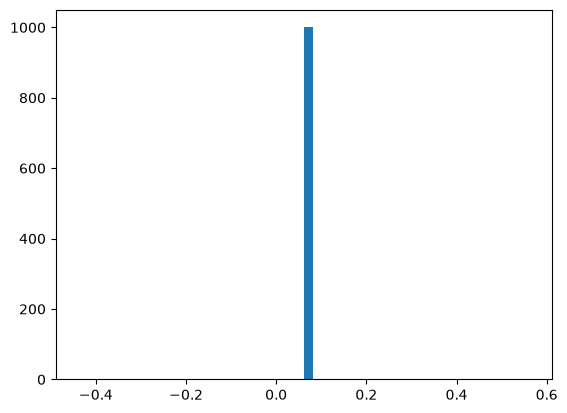

In [47]:
plt.hist(log_f_rn_g_xm[0,:],bins=50)
plt.show()

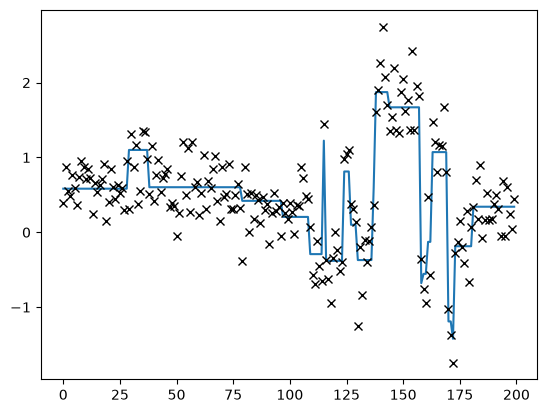

In [43]:
plt.plot(torch.arange(200),y_m_last[:200,0,0])
plt.plot(torch.arange(200),rgx_n.reshape((N,1,1))[:200,0,0],'kx')

In [10]:
log_f_r_n.shape

torch.Size([1, 10000])

In [11]:
log_f_rn_g_yn.shape

torch.Size([10000, 1])

In [81]:
dist = torch.distributions.MultivariateNormal(
    loc=torch.tensor([0.0]),
    covariance_matrix=torch.tensor([[0.1]])
)
dist.log_prob(dist.sample((1000,))).logsumexp(dim=0) - torch.log(torch.tensor(1000, dtype=dist.log_prob(dist.sample((1000,))).dtype))

tensor(-0.1184)

In [56]:
log_f_rn_g_yn.logsumexp(dim=0) - torch.log(torch.tensor(log_f_rn_g_yn.shape[0],dtype=torch.float))

tensor([-0.1086])

In [ ]:
log_f_rn_g_xm

tensor([[ 0.0612,  0.0612,  0.0612,  ...,  0.0612,  0.0612,  0.0612],
        [-0.1885, -0.1885, -0.1885,  ..., -0.1885, -0.1885, -0.1885],
        [ 0.2254,  0.2254,  0.2254,  ...,  0.2254,  0.2254,  0.2254],
        ...,
        [-1.5890, -1.5890, -1.5890,  ..., -1.5890, -1.5890, -1.5890],
        [ 0.2272,  0.2272,  0.2272,  ...,  0.2272,  0.2272,  0.2272],
        [ 0.2323,  0.2323,  0.2323,  ...,  0.2323,  0.2323,  0.2323]])

In [30]:
log_f_rn_g_xm.shape

torch.Size([10000, 1000])

In [28]:
log_f_rn_g_yn

tensor([[ 0.0612],
        [-0.1885],
        [ 0.2254],
        ...,
        [-1.5890],
        [ 0.2272],
        [ 0.2323]])

In [24]:
-torch.sum(dist.log_prob(dist.sample((1000,)))) / 1000

tensor(0.2636)

In [26]:
np.log(2*np.pi*np.e*0.1)/2

np.float64(0.26764598670764983)

In [174]:
log_f_rn_g_xm.shape

torch.Size([10000, 1000])

In [173]:
f_RgX_m

MultivariateNormal(loc: torch.Size([10000, 1000, 1]), covariance_matrix: torch.Size([10000, 1000, 1, 1]))

In [169]:
y_m_last.shape

torch.Size([10000, 1000, 1])

In [167]:
rgx_n.shape

torch.Size([10000, 1])

In [170]:
rgx_n.reshape((N,1,1)).shape

torch.Size([10000, 1, 1])

In [156]:
y_m.reshape((N,M,W,1)).shape

torch.Size([10000, 1000, 50, 1])

In [164]:
x_m.shape

torch.Size([10000000, 50, 1])

In [ ]:
y_m.reshape((N,M,W,1))

In [163]:
y_n[0,:,:].repeat_interleave(M,dim=0).reshape((N,M,1))[-1,:,0]

tensor([-1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801, -1.0801,
        -1.0801, -1.0801, -1.0801, -1.08

In [159]:
y_n

tensor([[[ 0.5200],
         [ 0.5200],
         [ 0.5200],
         ...,
         [ 1.9831],
         [ 1.9831],
         [-1.0801]]])

In [149]:
rgx.shape

torch.Size([1, 10000, 1])

In [147]:
y_xgy

tensor([[[ 2.0682],
         [ 0.9332],
         [ 0.9332],
         ...,
         [-0.2565],
         [-0.2565],
         [-0.2565]],

        [[ 1.1535],
         [ 1.1535],
         [ 1.1535],
         ...,
         [-0.2565],
         [-0.2565],
         [-0.2565]],

        [[ 2.3777],
         [ 2.3777],
         [ 2.3777],
         ...,
         [ 0.3675],
         [ 0.3675],
         [ 0.3675]],

        ...,

        [[ 0.2742],
         [ 0.2742],
         [ 0.2742],
         ...,
         [-0.0263],
         [-0.0263],
         [-0.4256]],

        [[-0.7145],
         [-0.7145],
         [-0.7145],
         ...,
         [-0.4256],
         [-0.4256],
         [-0.4256]],

        [[ 0.0248],
         [ 0.0248],
         [ 0.7032],
         ...,
         [-0.4256],
         [-0.4256],
         [-0.4256]]])

In [148]:
y

tensor([[[-0.2565],
         [-0.2565],
         [ 0.3675],
         ...,
         [-0.4256],
         [-0.4256],
         [-0.4256]]])

In [136]:
rgx.shape

torch.Size([1, 50000, 1])

In [142]:
y.shape

torch.Size([1, 10000, 1])

In [141]:
y[0,:,:].shape

torch.Size([10000, 1])

In [137]:
ycut

tensor([[ 0.3755,  0.3755,  0.3755,  ...,  1.5371, -0.2178, -0.2178],
        [ 1.2700,  1.2700,  1.2700,  ...,  0.1105,  0.1105,  0.1105],
        [ 0.1105,  0.3454,  0.3454,  ...,  2.1392,  2.1392,  2.1392],
        ...,
        [-0.6314, -0.6314, -0.6314,  ..., -0.5812, -0.5812, -0.5812],
        [-0.2146, -0.2146, -0.2146,  ...,  0.4364,  0.4364,  0.4364],
        [ 0.4364,  0.4364,  0.4364,  ..., -1.0669, -1.0669,  1.0075]])

In [ ]:
def I_RY_gaussian_mc(model, data_generator, N_XRY=10000):
    x, y = data_generator((1, N_XR))
    mean, L, _ = model(x)
    # time, output_size = mean.shape
    f_RgX = torch.distributions.MultivariateNormal(
        loc=mean,
        scale_tril=L,
    )
    rgx = f_RgX.rsample()

def I_RY_gaussian_mc_alt(model, data_generator, N_RgX=100, N_Y=100):
    x, y = data_generator((N_Y, N_RgX))
    mean, L, _ = model(x)
    f_RgX = torch.distributions.MultivariateNormal(
        loc=mean,
        scale_tril=L,
    )
    rgx = f_RgX.rsample()

In [ ]:
def I_XR_gaussian_mc_alt(model, data_generator, N_RgX=1000, N_X=1000):
    x = data_generator((1, N_X))
    mean, L, _ = model(x)
    time, output_size = mean.shape[1], mean.shape[2]
    f_RgX = torch.distributions.MultivariateNormal(
        loc=mean,
        scale_tril=L,
    ) # dim (1, time, output_size)
    rgx = f_RgX.rsample((N_RgX,)) # dim (N_RgX, time, output_size)
    f_rgx = f_RgX.log_prob(rgx).exp() # dim (N_RgX, output_size, time, output_size)
    x_ = data_generator((N_RgX, N_X))
    mean_, L_, _ = model(x_)
    f_RgX_ = torch.distributions.MultivariateNormal(
        loc=mean_,
        scale_tril=L_,
    )
    f_rgx_ = f_RgX_.log_prob(rgx).exp() # dim (N_RgX, time)
    f_r = f_rgx_.sum(dim=0,keepdims=True) / N_X
    return torch.sum(torch.log2(f_rgx / f_r)) / (N_RgX * N_X)

In [167]:
T = 1000
N_RgX = 1000
x, y = gaussian_change_point_process(
    T=T,
    B=1,
    hazard=0.1,
    emission_cov=torch.tensor([[0.1]]),
)
mean = y
f_RgX = torch.distributions.MultivariateNormal(
    loc=mean,
    covariance_matrix=torch.tensor([[0.1]]),
)
rgx = f_RgX.rsample((N_RgX,)) # dim (N_RgX, output_size, T, output_size)
f_rgx = f_RgX.log_prob(rgx).exp() # dim (N_RgX, output_size, T)
x_, y_ = gaussian_change_point_process(
    T=T,
    B=N_RgX,
    hazard=0.1,
    emission_cov=torch.tensor([[0.1]]),
)
# we need f_rgx_ below to be of dim (N_RgX, T, T)
f_RgX_ = torch.distributions.MultivariateNormal(
    loc=y_.unsqueeze(3),
    covariance_matrix=torch.tensor([[0.1]]),
    # batch_shape=(N_RgX,T),
    # event_shape=(1,),
) # dim (N_RgX, T, output_size)
f_rgx_ = f_RgX_.log_prob(rgx).exp() # dim (N_RgX, N_RgX, T)
f_r = f_rgx_.sum(dim=1,keepdims=True) / T
print(torch.sum(torch.log2(f_rgx/f_r)) / (N_RgX * T))

tensor(1.8718)


In [150]:
y_.shape

torch.Size([500, 1000, 1])

In [155]:
y_.unsqueeze(3).shape

torch.Size([500, 1000, 1, 1])

In [146]:
f_RgX

MultivariateNormal(loc: torch.Size([1, 1000, 1]), covariance_matrix: torch.Size([1, 1000, 1, 1]))

In [160]:
f_r.shape

torch.Size([500, 1, 1000])

In [161]:
f_r

tensor([[[0.3719, 0.2054, 0.3601,  ..., 0.3302, 0.3299, 0.3506]],

        [[0.4392, 0.4654, 0.4645,  ..., 0.4139, 0.4124, 0.3332]],

        [[0.3779, 0.3409, 0.3868,  ..., 0.3823, 0.3372, 0.3919]],

        ...,

        [[0.2659, 0.3522, 0.3499,  ..., 0.3376, 0.3296, 0.3318]],

        [[0.4037, 0.4026, 0.3873,  ..., 0.3932, 0.3869, 0.3976]],

        [[0.3468, 0.4458, 0.2959,  ..., 0.4802, 0.4010, 0.4743]]])

In [138]:
f_rgx.shape

torch.Size([500, 1, 1000])

In [139]:
rgx.shape

torch.Size([500, 1, 1000, 1])

In [148]:
rgx.squeeze(3).shape

torch.Size([500, 1, 1000])

In [158]:
f_rgx_.shape

torch.Size([500, 1000, 1000])

In [126]:
f_RgX_

MultivariateNormal(loc: torch.Size([500, 1000, 1]), covariance_matrix: torch.Size([500, 1000, 1, 1]))

In [128]:
f_rgx_.shape

torch.Size([500, 500, 1000])

In [120]:
y

tensor([[[-0.7383],
         [-0.7383],
         [-0.3000],
         [-0.3000],
         [-0.3000],
         [-0.3000],
         [-0.3000],
         [-0.3000],
         [-0.3000],
         [-0.3000],
         [-0.3000],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [-0.1981],
         [ 1.4180],
         [ 1.4180],
         [ 1.4180],
         [ 1.4180],


In [119]:
y_

tensor([[[-0.3333],
         [-0.3333],
         [-0.3333],
         ...,
         [ 0.0481],
         [ 0.0481],
         [ 0.0481]],

        [[ 1.1881],
         [ 1.1881],
         [ 1.1881],
         ...,
         [ 0.0022],
         [ 0.0022],
         [ 0.0022]],

        [[-1.2184],
         [-1.2184],
         [-1.2184],
         ...,
         [-1.6764],
         [-1.6764],
         [-1.5803]],

        ...,

        [[ 0.9215],
         [-0.8810],
         [-0.8810],
         ...,
         [ 0.4039],
         [ 0.4039],
         [ 0.4039]],

        [[-0.1908],
         [-0.1908],
         [ 0.6076],
         ...,
         [-0.1039],
         [-0.1039],
         [-0.1039]],

        [[-1.2088],
         [-1.2088],
         [-1.2088],
         ...,
         [-0.6794],
         [-0.6794],
         [-0.6794]]])

(array([107.,  64.,  45.,  33.,  54.,  29.,  34.,  28.,  41.,  65.]),
 array([3.93734692e-04, 1.26503482e-01, 2.52613246e-01, 3.78722996e-01,
        5.04832745e-01, 6.30942464e-01, 7.57052243e-01, 8.83162022e-01,
        1.00927174e+00, 1.13538146e+00, 1.26149118e+00]),
 <BarContainer object of 10 artists>)

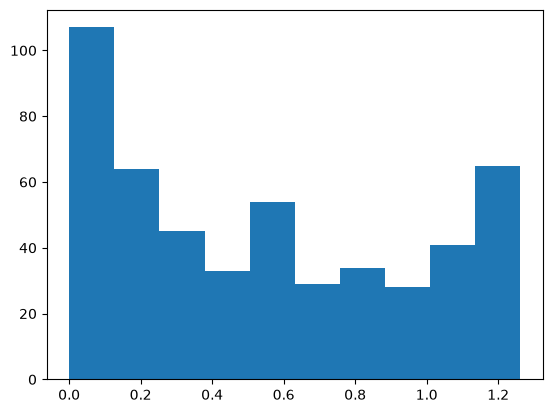

In [144]:
plt.hist(f_rgx_[:,0,0])

In [101]:
y_.shape

torch.Size([1000, 1000, 1])

In [90]:
f_RgX

MultivariateNormal(loc: torch.Size([1, 1000, 1]), covariance_matrix: torch.Size([1, 1000, 1, 1]))

In [87]:
rgx.shape

torch.Size([1000, 1, 1000, 1])

(array([  5.,  24.,  67., 151., 258., 232., 160.,  73.,  23.,   7.]),
 array([-0.44605237, -0.2350283 , -0.02400422,  0.18701988,  0.39804393,
         0.60906798,  0.82009214,  1.03111625,  1.24214029,  1.45316434,
         1.66418839]),
 <BarContainer object of 10 artists>)

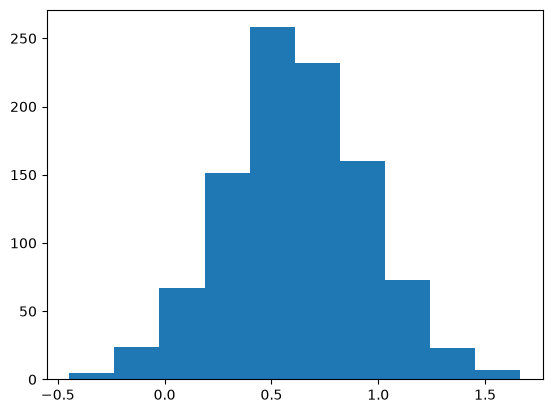

In [96]:
plt.hist(rgx[:,0,0,0])

(array([ 12.,  17.,  55., 149., 217., 284., 147.,  85.,  29.,   5.]),
 array([-3.9131763 , -3.12370396, -2.33423138, -1.54475904, -0.75528646,
         0.03418612,  0.82365823,  1.61313081,  2.40260339,  3.19207597,
         3.98154831]),
 <BarContainer object of 10 artists>)

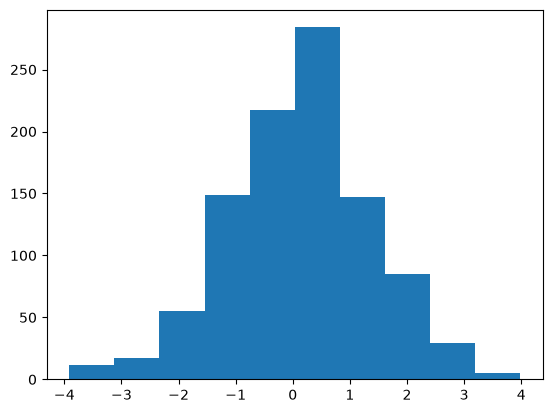

In [97]:
plt.hist(rgx[0,0,:,0])

(array([ 12.,  26.,  41., 136., 139., 257., 194., 112.,  45.,  38.]),
 array([-3.50598764, -2.85507298, -2.20415831, -1.55324364, -0.90232897,
        -0.2514143 ,  0.39950037,  1.05041504,  1.70132971,  2.35224438,
         3.00315928]),
 <BarContainer object of 10 artists>)

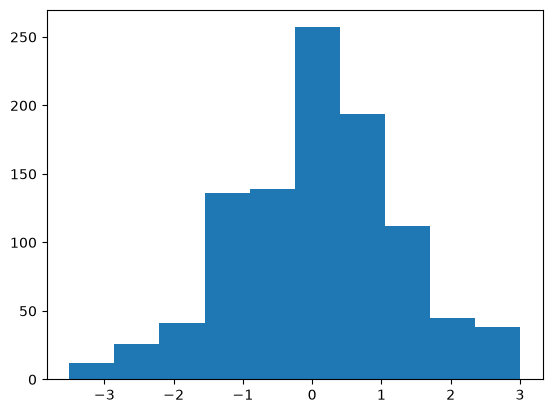

In [98]:
plt.hist(torch.flatten(y))

In [6]:
mean = torch.arange(10, dtype=torch.float).unsqueeze(1)  # Example shape (time, output_dim)
scale = torch.eye(1).expand(10, 1, 1)  # Example shape (time, output_dim, output_dim)

In [26]:
dists = torch.distributions.MultivariateNormal(
    loc=mean,
    scale_tril=scale,
)
sample = dists.rsample((5,))
sample.shape

torch.Size([5, 10, 1])

In [29]:
dists.log_prob(sample)

tensor([[-1.2559, -1.1923, -1.4591, -0.9511, -1.0226, -1.2357, -1.2681, -1.2528,
         -0.9303, -0.9190],
        [-1.8494, -1.0446, -3.1281, -0.9620, -0.9463, -1.1860, -1.7401, -0.9892,
         -0.9203, -2.0476],
        [-1.6045, -0.9226, -0.9961, -1.5181, -1.8078, -1.8119, -1.1600, -1.2112,
         -1.0140, -2.4645],
        [-0.9418, -1.4433, -2.1409, -0.9436, -0.9431, -1.2512, -0.9192, -2.2685,
         -2.0496, -1.1519],
        [-1.0549, -1.1898, -1.2031, -0.9380, -0.9714, -1.9172, -1.3323, -2.7254,
         -1.0900, -0.9341]])

In [41]:
sample[:,0,:].unsqueeze(1)

tensor([[[ 0.8210]],

        [[-1.3642]],

        [[-1.1709]],

        [[ 0.2140]],

        [[ 0.5214]]])

In [40]:
dists.log_prob(sample[:,0,:].unsqueeze(1))

tensor([[ -1.2559,  -0.9350,  -1.6140,  -3.2930,  -5.9720,  -9.6510, -14.3301,
         -20.0091, -26.6881, -34.3671],
        [ -1.8494,  -3.7135,  -6.5777, -10.4418, -15.3060, -21.1701, -28.0343,
         -35.8984, -44.7626, -54.6268],
        [ -1.6045,  -3.2754,  -5.9463,  -9.6172, -14.2881, -19.9590, -26.6299,
         -34.3009, -42.9718, -52.6427],
        [ -0.9418,  -1.2279,  -2.5139,  -4.7999,  -8.0859, -12.3719, -17.6579,
         -23.9440, -31.2300, -39.5160],
        [ -1.0549,  -1.0335,  -2.0120,  -3.9906,  -6.9692, -10.9477, -15.9263,
         -21.9049, -28.8834, -36.8620]])

In [34]:
dists.log_prob(sample[1,:, :])

tensor([-1.8494, -1.0446, -3.1281, -0.9620, -0.9463, -1.1860, -1.7401, -0.9892,
        -0.9203, -2.0476])

In [28]:
dists.log_prob(sample).shape

torch.Size([5, 10])

In [24]:
sample

tensor([[[ 1.9042],
         [ 1.2772],
         [ 1.6566],
         [ 2.6723],
         [ 4.3658],
         [ 5.6310],
         [ 6.7739],
         [ 6.3746],
         [ 7.9014],
         [ 8.6517]],

        [[ 1.2972],
         [-1.9298],
         [ 2.1287],
         [ 2.9682],
         [ 4.2539],
         [ 4.0006],
         [ 4.8360],
         [ 7.9637],
         [ 8.2820],
         [ 9.4167]],

        [[-0.5542],
         [ 0.8974],
         [ 2.3278],
         [ 2.9566],
         [ 3.0369],
         [ 4.3425],
         [ 3.8272],
         [ 7.5470],
         [ 6.6271],
         [10.5624]],

        [[-1.4301],
         [ 0.2064],
         [ 2.1139],
         [ 3.4721],
         [ 3.4401],
         [ 5.6186],
         [ 5.5931],
         [ 6.3721],
         [ 7.4302],
         [ 7.9241]],

        [[-0.9443],
         [ 0.3971],
         [ 4.1288],
         [ 4.2445],
         [ 3.1096],
         [ 5.5034],
         [ 6.1840],
         [ 6.9884],
         [ 6.6048],
         [ 9

In [23]:
sample.view(5, 10, 1)

tensor([[[ 1.9042],
         [ 1.2772],
         [ 1.6566],
         [ 2.6723],
         [ 4.3658],
         [ 5.6310],
         [ 6.7739],
         [ 6.3746],
         [ 7.9014],
         [ 8.6517]],

        [[ 1.2972],
         [-1.9298],
         [ 2.1287],
         [ 2.9682],
         [ 4.2539],
         [ 4.0006],
         [ 4.8360],
         [ 7.9637],
         [ 8.2820],
         [ 9.4167]],

        [[-0.5542],
         [ 0.8974],
         [ 2.3278],
         [ 2.9566],
         [ 3.0369],
         [ 4.3425],
         [ 3.8272],
         [ 7.5470],
         [ 6.6271],
         [10.5624]],

        [[-1.4301],
         [ 0.2064],
         [ 2.1139],
         [ 3.4721],
         [ 3.4401],
         [ 5.6186],
         [ 5.5931],
         [ 6.3721],
         [ 7.4302],
         [ 7.9241]],

        [[-0.9443],
         [ 0.3971],
         [ 4.1288],
         [ 4.2445],
         [ 3.1096],
         [ 5.5034],
         [ 6.1840],
         [ 6.9884],
         [ 6.6048],
         [ 9

In [31]:
dist = torch.distributions.MultivariateNormal(
    loc=torch.tensor([0.]),
    scale_tril=torch.tensor([[1.]]),
)

In [32]:
dist.rsample((100,100,100))

tensor([[[[-0.3154],
          [ 1.2692],
          [-0.5540],
          ...,
          [-0.8728],
          [ 0.4070],
          [-0.7998]],

         [[-0.8785],
          [-0.6993],
          [-0.2129],
          ...,
          [ 1.6736],
          [-0.0225],
          [-0.2555]],

         [[-0.6655],
          [-0.8768],
          [ 0.0734],
          ...,
          [-0.2033],
          [-0.4615],
          [ 0.1969]],

         ...,

         [[ 0.6223],
          [ 0.4025],
          [-0.5557],
          ...,
          [-0.6206],
          [-0.5946],
          [ 0.6742]],

         [[-0.8091],
          [-1.8993],
          [-0.3291],
          ...,
          [ 0.7631],
          [ 0.9572],
          [-1.1013]],

         [[-1.3841],
          [-0.4601],
          [ 1.2325],
          ...,
          [-1.7672],
          [ 0.8628],
          [ 0.8340]]],


        [[[-1.9893],
          [-2.3475],
          [ 0.0085],
          ...,
          [ 0.0507],
          [ 0.0428],
     